# NumPy: Fast Arithmetic on Arrays of Numbers

**Course:** Computing with Python

**Today you learn:** **NumPy**, the library that makes calculations on many numbers at once short, readable and fast. It is the foundation of scientific Python (Matplotlib and Pandas are built on it).

### Goals
By the end of this session you will be able to:
1. Create a NumPy array and explain the difference with a list.
2. Compute with a whole array at once (no loop), and get statistics.
3. Select elements with indexes, slices and conditions.
4. Work with 2-D arrays (matrices): shape, rows, columns, `axis`.
5. Create arrays quickly: `zeros`, `ones`, `arange`, `linspace`, random numbers.
6. Reshape and glue arrays.
7. Use arrays for mathematics: functions, dot product, matrix product, linear systems.

### Outline
| Part | Topic |
|---|---|
| 0 | Why NumPy? |
| 1 | Our first array |
| 2 | Computing with arrays |
| 3 | Indexing, slicing and conditions |
| 4 | Two dimensions: matrices |
| 5 | Creating arrays quickly |
| 6 | Statistics and the `axis` |
| 7 | Reshaping and gluing |
| 8 | NumPy for mathematics |
| 9 | Summary and self-check |



To start, let's import numpy (`np` is the usual nickname of `numpy`).

In [ ]:
import numpy as np

---
## Part 0. Why NumPy?

Suppose we have five temperatures in Celsius and we want them in Fahrenheit ($F = 1.8\,C + 32$). With a list, we need a loop:

In [ ]:
celsius = [20, 25, 30, 35, 40]

fahrenheit = []
for c in celsius:
    fahrenheit.append(1.8 * c + 32)

print(fahrenheit)

With NumPy, we write the **formula** and it is applied to every element:

In [ ]:
# Using numpy
celsius = np.array([20, 25, 30, 35, 40])
fahrenheit = 1.8 * celsius + 32
print(fahrenheit)
print(type(fahrenheit))

**Key idea:** a NumPy array behaves like a mathematical **vector**: operations apply to **all** the elements at once. No loop, shorter code, and much faster on large data.



---
## Part 1. Our first array

An array is created from a **list** with `np.array(...)`.

In [ ]:
A = np.array([10, 20, 30, 40, 50])
print(A)
print(type(A))

Three properties tell us everything about an array:

In [ ]:
print(A.shape)    # the size in each dimension (a tuple)
print(A.size)     # the total number of elements
print(A.dtype)    # the type of the numbers stored

`(5,)` is a tuple with one element: a **1-D** array of 5 numbers. The `dtype` tells whether the numbers are integers (`int64`) or decimals (`float64`).

**Notice:** the numbers (16, 32, 64) indicate the amount of memory in bits allocated to store a single value.
- More bits → Higher precision and larger range of numbers, but uses more RAM.
- Fewer bits → Lower memory footprint, but lower precision and smaller range.



**Warning:**
- `np.array(1, 2, 3)` is wrong
- To fix this, give **one list** instead, `np.array([1, 2, 3])`.



**Your turn.**

Create the array `x` with the numbers 2, 4, 6, 8, 10 and print its `shape` and its `size`.

In [ ]:
# Your code here
x = np.array([2,4,6,8,10])
x.shape

---
## Part 2. Computing with arrays

**Predict:** what do `a + b` and `a * 2` give for **lists**, and for **arrays**?

In [ ]:
# Lists
a = [1, 2, 3]
b = [4, 5, 6]
print(a + b)
print(a * 2)

In [ ]:
# Numpy
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
print(a + b)
print(a * 2)

For lists, `+` **glues** and `*` **repeats**. For arrays, they are the mathematical operations, **element by element**.

In [ ]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

print(a - b)
print(a * b)      # element by element, NOT the dot product
print(a ** 2)
print(b / a)
print(b > 4)      # A comparison also works on the whole array and gives `True`/`False` for each element:

### Statistics in one word

In [ ]:
marks = np.array([12, 15, 9, 18, 7, 14])

print(marks.sum())
print(marks.mean())
print(marks.min(), marks.max())
print(marks.std())
print(marks.argmax())      # the POSITION of the maximum

**Warning:** two arrays can be combined only if their shapes agree. `np.array([1, 2, 3]) + np.array([1, 2])` gives a `ValueError`.



**Your turn.**

The prices of five items are `[1200, 850, 3000, 450, 990]` (in CFA francs). Compute the prices **with a 18% tax** (multiply by 1.18) and print the total.

In [ ]:
prices = np.array([1200, 850, 3000, 450, 990])

# Your code here

---
## Part 3. Indexing, slicing and conditions

Exactly like lists: the first position is **0**, negative indexes count from the end, `start:stop` excludes `stop`.

In [ ]:
A = np.array([10, 20, 30, 40, 50, 60])

print(A[0])
print(A[-1])
print(A[1:4])
print(A[:3])
print(A[::2])      # every second element

Unlike a list slice, a slice of an array is a **view** of the same data: modifying it modifies the original. Use `.copy()` to get an independent array.



In [ ]:
# Lists
a = [10, 20, 30, 40]
b = a[1:3]  # b is a NEW list: [20, 30]

b[0] = 99   # Modify b
print(a)    # [10, 20, 30, 40] -> Original list 'a' is UNCHANGED
print(b)

In [ ]:
# Numpy arrays
arr = np.array([10, 20, 30, 40])
view = arr[1:3]  # view points to the same memory as arr

view[0] = 99     # Modify view
print(arr)       # [10, 99, 30, 40] -> Original 'arr' IS MODIFIED!
print(view)

How to Get an Independent Array?

If you want the NumPy slice to behave like a independent copy, explicitly call `.copy()`:

In [ ]:
arr = np.array([10, 20, 30, 40])
independent = arr[1:3].copy()  # Allocates new memory

independent[0] = 99
print(arr)  # [10, 20, 30, 40] -> Original array remains safe!
print(independent)

### Boolean indexing: select with a condition

This is the most useful trick of NumPy. A condition gives an array of `True`/`False`; putting it in brackets keeps the elements where it is `True`.

In [ ]:
temperatures = np.array([29, 31, 27, 35, 34, 26])

hot = temperatures > 30
print(hot)
print(temperatures[hot])

In [ ]:
print(temperatures[temperatures > 30])        # in one line
print((temperatures > 30).sum())              # how many are hot? (True counts as 1)

We can also **modify** the selected elements:

In [ ]:
marks = np.array([12, 15, 9, 18, 7, 14])
marks[marks < 10] = 10        # raise every mark below 10 to 10
print(marks)

**Your turn.**

With `marks = np.array([12, 15, 9, 18, 7, 14])`, print the marks above the mean, and the number of marks that are **at least 10**.

In [ ]:
marks = np.array([12, 15, 9, 18, 7, 14])

# Your code here


---
## Part 4. Two dimensions: matrices

A list of lists gives a **2-D array**: rows and columns.

In [ ]:
M = np.array([[1, 2, 3],
              [4, 5, 6]])
print(M)
print(M.shape)     # (rows, columns)
print(M.ndim)      # number of dimensions
print(M.size)

`(2, 3)` means 2 rows and 3 columns, **always in this order**.

### Indexing: `M[row, column]`

In [ ]:
print(M[0, 2])        # row 0, column 2
print(M[1, 0])
print(M[1, :])        # the whole row 1
print(M[:, 1])        # the whole column 1
print(M[:, 1:])       # all rows, columns 1 and after

**Key idea:** in `M[rows, columns]`, a `:` means "all". Remember the order: **rows first**.

The transpose of a matrix swaps rows and columns:

In [ ]:
print(M.T)      # Transpose of M
print(M.T.shape)

**Your turn.** Consider
```python
T = np.array([[29, 31, 30, 27],
              [24, 26, 25, 22],
              [35, 36, 34, 33]])
```
(rows: Dakar, Saint-Louis, Tambacounda; columns: four days). Print the temperature of Tambacounda on day 2 (the third column), the whole row of Dakar, and the first two days of every city.

In [ ]:
T = np.array([[29, 31, 30, 27],
              [24, 26, 25, 22],
              [35, 36, 34, 33]])

# Your code here

---
## Part 5. Creating arrays quickly

We do not type large arrays by hand.

In [ ]:
print(np.zeros((2,3)))
print(np.ones((2, 3)))          # the shape is a tuple
print(np.full((2, 2), 7))
print(np.eye(3))                # the identity matrix

### `arange` and `linspace`

- `np.arange(start, stop, step)` works like `range`: `stop` **excluded**, the **step** is chosen.
- `np.linspace(start, stop, n)`: `n` equally spaced numbers, `stop` **included**, the **number of points** is chosen.

In [ ]:
print(np.arange(0, 10, 2))
print(np.linspace(0, 1, 6))

`linspace` is the tool to prepare the $x$ values of a graph of a function.

### Random numbers

In [ ]:
np.random.seed(123)                    # same "random" numbers at each run
print(np.random.rand(3))               # 3 numbers uniform in [0, 1)
print(np.random.randint(1, 7, 10))     # 10 dice throws (1 to 6)

`seed` makes the experiment **reproducible**: run the cell again and you get the same numbers.

**Your turn.**

Create the array of the 11 numbers $0, 0.1, 0.2, \dots, 1$ in two different ways (with `arange` and with `linspace`).

In [ ]:
# Your code here


---
## Part 6. Statistics and the `axis`

For a matrix, `M.sum()` adds **everything**. To add along rows or columns, we give the **axis**:
- `axis=0`: go **down** the rows: one result **per column**.
- `axis=1`: go **across** the columns: one result **per row**.

Example

In [ ]:
M = np.array([[1, 2, 3],
              [4, 5, 6]])

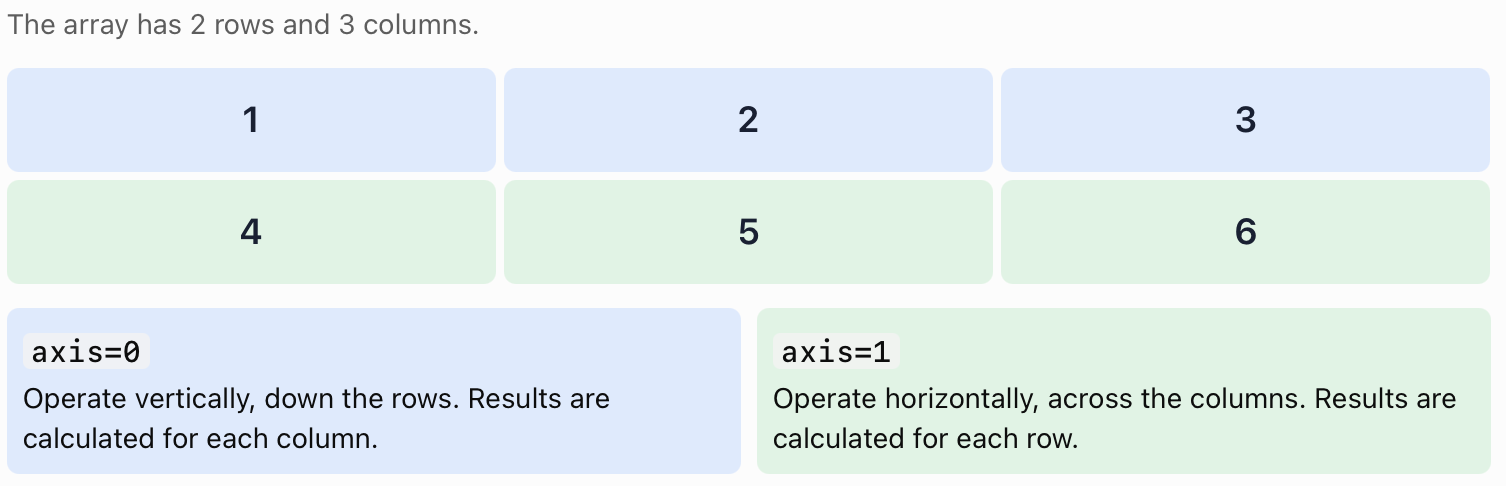

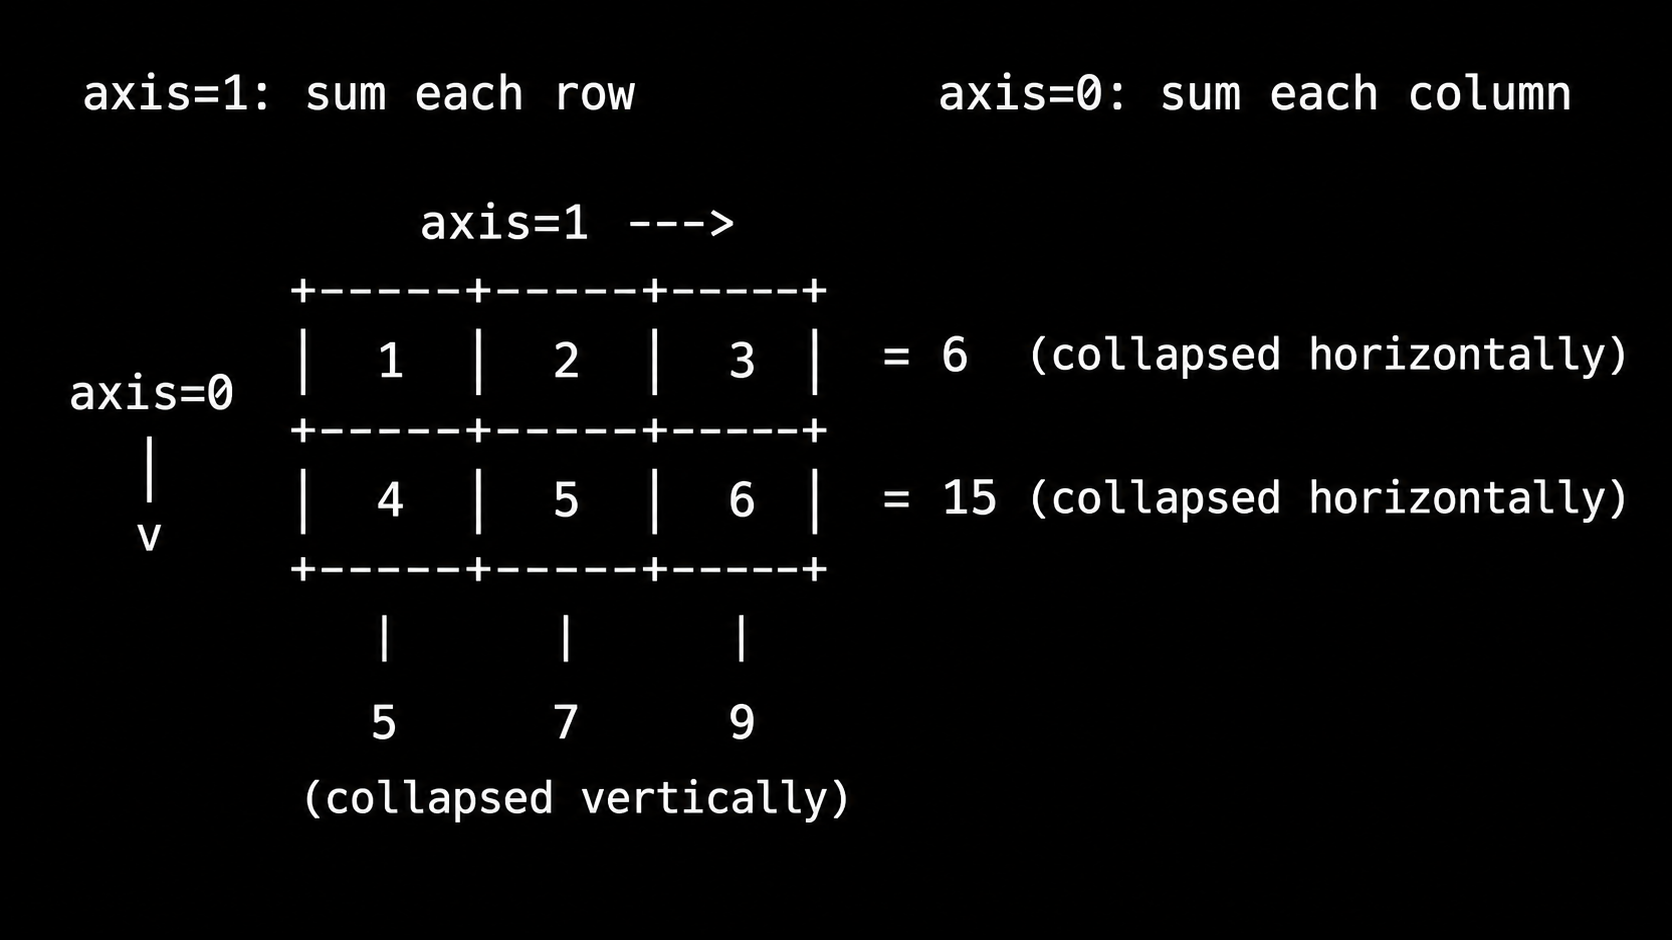

Now, we can sum along axis=0

In [ ]:
print(np.sum(M, axis=0))      # Output: [5 7 9]

NumPy adds the values in each column:

- Column 0: (1 + 4 = 5)
- Column 1: (2 + 5 = 7)
- Column 2: (3 + 6 = 9)


Likewise, we can sum along axis=1

In [ ]:
print(np.sum(M, axis=1))      # Output: [6 15]

NumPy adds the values in each row:

- Row 0: (1 + 2 + 3 = 6)
- Row 1: (4 + 5 + 6 = 15)

The same principle applies to np.mean(), np.min(), np.max(), and many other NumPy functions.

In [ ]:
import numpy as np
T = np.array([[29, 31, 30, 27],
              [24, 26, 25, 22],
              [35, 36, 34, 33]])

print(T.mean(axis=1))             # the mean temperature of each city
print(T.max(axis=0))              # the hottest value of each day
print(T.mean(axis=1).argmax())    # the index of the hottest city

**Memory trick:** the axis you give is the one that **disappears**: a $(3, 4)$ array summed over `axis=0` becomes $(4,)$.

**Your turn.**

With the matrix `T` above, print the mean temperature of each **day**.

In [ ]:
# Your code here

---
## Part 7. Reshaping and gluing

- `reshape` re-organises the **same numbers** in a new shape. The total number of elements must stay the same.
- `ravel()` flattens a multi-dimensional array into a contiguous 1D array.

In [ ]:
A = np.arange(1, 7)
print(A)
print(A.reshape(2, 3))
print(A.reshape(3, 2))
print(A.ravel())            # flatten to 1-D

**Warning:** `np.arange(6).reshape(4, 2)` gives a `ValueError`, because $4 \times 2 \neq 6$.



---
## Part 8. NumPy for mathematics

### Functions applied to arrays
`np.sqrt`, `np.sin`, `np.cos`, `np.exp`, `np.log`, `np.abs` work on every element.

---
## Vectors

A **vector** is a list of numbers. In NumPy it is a 1-D array. We use two vectors:

$$\mathbf{a} = \begin{pmatrix} 1 \\ 2 \\ 3 \end{pmatrix}, \qquad \mathbf{b} = \begin{pmatrix} 4 \\ 5 \\ 6 \end{pmatrix}$$


In [ ]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
print(a)
print(b)
print(a.shape, b.shape)

### A1. Element-wise product: `a * b`

We multiply the numbers that are **in the same position**. The result is a **vector** with the same length.

$$
\mathbf{a} * \mathbf{b}
= \begin{pmatrix} 1 \\ 2 \\ 3 \end{pmatrix} * \begin{pmatrix} 4 \\ 5 \\ 6 \end{pmatrix}
= \begin{pmatrix} \color{#d62728}{1 \cdot 4} \\ \color{#1f77b4}{2 \cdot 5} \\ \color{#2ca02c}{3 \cdot 6} \end{pmatrix}
= \begin{pmatrix} \color{#d62728}{4} \\ \color{#1f77b4}{10} \\ \color{#2ca02c}{18} \end{pmatrix}
$$

The same idea works for `+`, `-`, `/` and `**`.

In [ ]:
print(a * b)       # [1*4, 2*5, 3*6]
print(a + b)       # [1+4, 2+5, 3+6]

### A2. Dot product: `np.dot(a, b)`

- Step 1: multiply element by element.
- Step 2: **add** everything. The result is **one number**, not a vector.

$$
\mathbf{a} \cdot \mathbf{b}
= \color{#d62728}{1 \cdot 4} + \color{#1f77b4}{2 \cdot 5} + \color{#2ca02c}{3 \cdot 6}
= \color{#d62728}{4} + \color{#1f77b4}{10} + \color{#2ca02c}{18}
= 32
$$

In one formula: $\mathbf{a} \cdot \mathbf{b} = a_0 b_0 + a_1 b_1 + \dots + a_{n-1} b_{n-1}$.

**Key idea:** dot product = element-wise product, then the sum.

You have 3 options:


1.   Use the manual method just shown, and then apply the sum to it.
2.   Use numpy np.dot(a, b)
3.   Use the shortcut `@`: a @ b



In [ ]:
# Option 1
step1 = a * b
print(step1)               # [ 4 10 18]  a vector
print(step1.sum())         # 32          step 2: the sum

# Option 2
print(np.dot(a, b))        # 32          NumPy does both steps at once

# Option 3
print(a @ b)               # 32          the same, with the operator @

### A3. The two products side by side

| | `a * b` | `np.dot(a, b)` |
|---|---|---|
| Name | element-wise product | dot product |
| Calculation | $(a_0 b_0,\; a_1 b_1,\; a_2 b_2)$ | $a_0 b_0 + a_1 b_1 + a_2 b_2$ |
| Result for our $\mathbf{a}, \mathbf{b}$ | `[ 4 10 18]` | `32` |
| Type of result | a vector (3 numbers) | one number |

**Warning:** both vectors must have the **same length**. `np.dot(np.array([1, 2, 3]), np.array([1, 2]))` gives a `ValueError`.

### A4. A useful example: the total price

A customer buys

-  2 breads at 500 francs (each),
-  1 box of milk at 1200 francs
-  and 3 trays of eggs at 300 francs (each).

The total is the dot product of the quantities and the prices:

$$
\begin{pmatrix} 2 \\ 1 \\ 3 \end{pmatrix} \cdot \begin{pmatrix} 500 \\ 1200 \\ 300 \end{pmatrix}
= 2 \cdot 500 + 1 \cdot 1200 + 3 \cdot 300 = 1000 + 1200 + 900 = 3100
$$

In [ ]:
quantities = np.array([2, 1, 3])
prices = np.array([500, 1200, 300])

print(quantities * prices)          # the cost of each item
print(np.dot(quantities, prices))   # the total

---
## Part B. Matrices: the element-wise product `A * B`

A **matrix** is a table of numbers (a 2-D array). We use

$$A = \begin{pmatrix} 1 & 2 \\ 3 & 4 \end{pmatrix}, \qquad B = \begin{pmatrix} 5 & 6 \\ 7 & 8 \end{pmatrix}$$

Exactly like vectors, the **element-wise product** `A * B` multiplies the numbers **in the same position**. The two matrices **must have the same shape**, and the result has this shape too.

$$
A * B
= \begin{pmatrix} 1 \cdot 5 & 2 \cdot 6 \\ 3 \cdot 7 & 4 \cdot 8 \end{pmatrix}
= \begin{pmatrix} 5 & 12 \\ 21 & 32 \end{pmatrix}
$$



In [ ]:
A = np.array([[1, 2],
              [3, 4]])
B = np.array([[5, 6],
              [7, 8]])

print(A * B)

**Warning:** this is **not** the matrix multiplication (also called matrix product). That one comes next.

---
## Part C. The matrix product, entry by entry

The matrix product $C = AB$ is built from **dot products**:

> The entry $C[i, j]$ is the **dot product of row $i$ of $A$ with column $j$ of $B$**.

The condition to satisfy (the inner dimension rule): the number of columns in the first matrix must equal the number of rows in the second matrix:

$(m \times \mathbf{n}) \cdot (\mathbf{n} \times p) = (m \times p)$

- The inner dimensions match ($\mathbf{n} = \mathbf{n}$)
- This will produce a result with the outer dimensions $(m \times p)$.


We use the same $A$ and $B$ as before. There are four entries to compute. The row of $A$ is <span style="color:#d62728">red</span>, the column of $B$ is <span style="color:#1f77b4">blue</span>, and the entry that we compute is <span style="color:#7b2cbf">purple</span>.



### Entry $C[0,0]$: row 0 of $A$ with column 0 of $B$

$$\begin{pmatrix} \color{#d62728}{1} & \color{#d62728}{2} \\ 3 & 4 \end{pmatrix}\begin{pmatrix} \color{#1f77b4}{5} & 6 \\ \color{#1f77b4}{7} & 8 \end{pmatrix}=\begin{pmatrix} \color{#7b2cbf}{19} & \cdot \\ \cdot & \cdot \end{pmatrix}$$

$$C[0,0] = \color{#d62728}{1}\cdot\color{#1f77b4}{5} + \color{#d62728}{2}\cdot\color{#1f77b4}{7} = \color{#7b2cbf}{5} + \color{#7b2cbf}{14} = \color{#7b2cbf}{19}$$

### Entry $C[0,1]$: row 0 of $A$ with column 1 of $B$

$$\begin{pmatrix} \color{#d62728}{1} & \color{#d62728}{2} \\ 3 & 4 \end{pmatrix}\begin{pmatrix} 5 & \color{#1f77b4}{6} \\ 7 & \color{#1f77b4}{8} \end{pmatrix}=\begin{pmatrix} \cdot & \color{#7b2cbf}{22} \\ \cdot & \cdot \end{pmatrix}$$

$$C[0,1] = \color{#d62728}{1}\cdot\color{#1f77b4}{6} + \color{#d62728}{2}\cdot\color{#1f77b4}{8} = \color{#7b2cbf}{6} + \color{#7b2cbf}{16} = \color{#7b2cbf}{22}$$

### Entry $C[1,0]$: row 1 of $A$ with column 0 of $B$

$$\begin{pmatrix} 1 & 2 \\ \color{#d62728}{3} & \color{#d62728}{4} \end{pmatrix}\begin{pmatrix} \color{#1f77b4}{5} & 6 \\ \color{#1f77b4}{7} & 8 \end{pmatrix}=\begin{pmatrix} \cdot & \cdot \\ \color{#7b2cbf}{43} & \cdot \end{pmatrix}$$

$$C[1,0] = \color{#d62728}{3}\cdot\color{#1f77b4}{5} + \color{#d62728}{4}\cdot\color{#1f77b4}{7} = \color{#7b2cbf}{15} + \color{#7b2cbf}{28} = \color{#7b2cbf}{43}$$

### Entry $C[1,1]$: row 1 of $A$ with column 1 of $B$

$$\begin{pmatrix} 1 & 2 \\ \color{#d62728}{3} & \color{#d62728}{4} \end{pmatrix}\begin{pmatrix} 5 & \color{#1f77b4}{6} \\ 7 & \color{#1f77b4}{8} \end{pmatrix}=\begin{pmatrix} \cdot & \cdot \\ \cdot & \color{#7b2cbf}{50} \end{pmatrix}$$

$$C[1,1] = \color{#d62728}{3}\cdot\color{#1f77b4}{6} + \color{#d62728}{4}\cdot\color{#1f77b4}{8} = \color{#7b2cbf}{18} + \color{#7b2cbf}{32} = \color{#7b2cbf}{50}$$

### All four entries together

$$
\begin{pmatrix} 1 & 2 \\ 3 & 4 \end{pmatrix}
\begin{pmatrix} 5 & 6 \\ 7 & 8 \end{pmatrix}
= \begin{pmatrix} 19 & 22 \\ 43 & 50 \end{pmatrix}
$$

Let us do exactly the same in Python

---
## Part D. `np.dot(A, B)` and `A @ B` for matrices

For 2-D arrays, `np.dot(A, B)` is the **matrix product**, and the operator `A @ B` gives **the same result**.

In [ ]:
print(np.dot(A, B))
print(A @ B)

So we have three different things for two matrices:

| Python | Name | $A$, $B$ above | Rule |
|---|---|---|---|
| `A * B` | element-wise product | $\begin{pmatrix} 5 & 12 \\ 21 & 32 \end{pmatrix}$ | same position times same position |
| `np.dot(A, B)` | matrix product | $\begin{pmatrix} 19 & 22 \\ 43 & 50 \end{pmatrix}$ | row of $A$ dot column of $B$ |
| `A @ B` | matrix product | $\begin{pmatrix} 19 & 22 \\ 43 & 50 \end{pmatrix}$ | the same as `np.dot` |

For vectors and 2-D arrays, `np.dot` and `@` always agree. We prefer `@` for matrices because it looks like the mathematics. (The two only differ for arrays with 3 or more dimensions, which we do not use.)

**Warning:** the most common mistake is to write `A * B` when you want the matrix product.

---
## Part 9. Summary and self-check

### Cheat sheet
```python
import numpy as np

A = np.array([1, 2, 3])               # from a list
A.shape  A.ndim  A.size  A.dtype      # properties
A + B   A * 2   A ** 2   A > 1        # element by element
A.sum()  A.mean()  A.std()  A.min()  A.max()  A.argmax()

A[0]  A[-1]  A[1:3]                   # indexes and slices
A[A > 1]                              # boolean indexing
M[i, j]   M[i, :]   M[:, j]           # 2-D: rows first
M.sum(axis=0)   M.mean(axis=1)        # axis 0: per column, axis 1: per row

np.zeros((2, 3))  np.ones(4)  np.full((2, 2), 7)  np.eye(3)
np.arange(0, 10, 2)   np.linspace(0, 1, 5)
np.random.seed(0)  np.random.rand(3)  np.random.randint(1, 7, 10)

M.reshape(2, 3)   M.ravel()   M.T
np.sin(x)  np.sqrt(x)  np.exp(x)      # on every element
a @ b    np.dot(a, b)    np.linalg.solve(A, b)
```

### List or array?
| | List | Array |
|---|---|---|
| `+` | glues | adds element by element |
| `* 2` | repeats | doubles each element |
| Contents | anything | numbers of one type |
| Speed on big data | slow | fast |
| Statistics | write a loop | `.mean()`, `.sum()` ... |

### Classic mistakes
| Mistake | Fix |
|---|---|
| `np.array(1, 2, 3)` | `np.array([1, 2, 3])` |
| `np.zeros(2, 3)` | `np.zeros((2, 3))` (a tuple) |
| `M[1][2]` confused with `M[1, 2]` | prefer `M[1, 2]` |
| `A * B` for the matrix product | use `A @ B` |
| `axis=0` and `axis=1` mixed up | the axis you give disappears |
| arrays of different shapes | check `.shape` first |
| `np.arange` with decimals | use `np.linspace` |

### Self-check
Answer without running the code, then check.

**1.** What is printed by `print([1, 2] * 2)` and by `print(np.array([1, 2]) * 2)`?

**2.** `M` has shape `(3, 4)`. What is the shape of `M.sum(axis=0)`? Of `M.mean(axis=1)`? Of `M.T`?

**3.** What does `A[A > 25]` do?

**4.** How many elements does `np.linspace(0, 1, 11)` contain? And `np.arange(0, 10, 2)`?

**5.** What is the difference between `A * B` and `A @ B` for two matrices?